In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Assuming the data is in a .dat file, we can read the data and assign it to arrays.
import numpy as np

# Function to read the .dat file and store values into arrays
def read_dat_file(file_path):
    # Read the .dat file
    data = np.loadtxt(file_path)
    
    # Split the columns into respective arrays
    pressure = data[:, 0]
    energy_density = data[:, 1]
    number_density = data[:, 2]
    chemical_potential = data[:, 3]
    
    return pressure, energy_density, number_density, chemical_potential

# Path to your .dat file
file_path = 'EOS_bag_2.dat'

# Extract arrays from the file
pressure, energy_density, number_density, chemical_potential = read_dat_file(file_path)


In [3]:
columns = ['Pressure', 'number_density', 'energy_density', 'chemical_potential']
data = {
    'Pressure': pressure,
    'number_density': number_density,
    'energy_density': energy_density,
    'chemical_potential': chemical_potential
}

df_quark = pd.DataFrame(data, columns=columns)
print(df_quark)

      Pressure  number_density  energy_density  chemical_potential
0     2.632985        0.264164      259.048977          990.604027
1     5.882597        0.273946      268.798769         1002.684564
2     9.251813        0.283966      278.907382         1014.765101
3    12.743530        0.294228      289.383513         1026.845638
4    16.360684        0.304735      300.235965         1038.926174
..         ...             ...             ...                 ...
63  576.759420        1.460469     1981.511044         1751.677852
64  594.585174        1.490893     2034.989989         1763.758389
65  612.780998        1.521737     2089.579156         1775.838926
66  631.351979        1.553004     2145.293806         1787.919463
67  650.303238        1.568743     2173.434416         1800.000000

[68 rows x 4 columns]


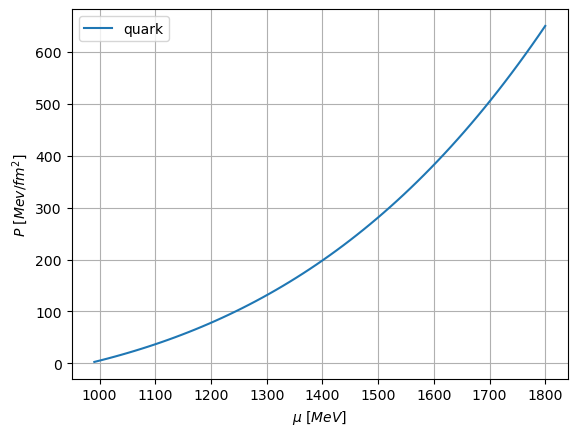

In [4]:
plt.plot(chemical_potential, pressure, label = "quark")
plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
plt.legend()
plt.grid()

In [13]:
n_had =np.linspace(0.08,1.5,20)
Gam_had = 2
m0_had = ((Gam_had-1)*(75.81)-(0.4054))/((Gam_had-1)*(0.08))
K_had = 0.4054/((0.08)**Gam_had)

def P_from_nb(n_list, K, Gam):
    p = K*(n_list)**(Gam)
    return p

def mu_from_nb(n_list, K, Gam, m0):
    t1 = ((K*Gam)/(Gam - 1))*((n_list)**(Gam - 1))
    re = t1 + m0
    return re

def e_from_n(n_list, K, Gam, m0):
    t1 = (K * ((n_list) ** Gam)) / (Gam - 1)
    t2 = t1 + (m0 * (n_list))
    return t2


mu=mu_from_nb(n_had,K_had,Gam_had,m0_had)
p=P_from_nb(n_had,K_had,Gam_had)
e=e_from_n(n_had,K_had,Gam_had,m0_had)

In [14]:
columns = ['Pressure', 'number_density', 'energy_density', 'chemical_potential']
data_hadronic = {
    'Pressure': p,
    'number_density': n_had,
    'energy_density': e,
    'chemical_potential': mu
}

df_hadronic = pd.DataFrame(data_hadronic, columns=columns)
print(df_hadronic)

      Pressure  number_density  energy_density  chemical_potential
0     0.405400        0.080000       75.810000          952.692500
1     1.516670        0.154737      147.365042          962.160724
2     3.335566        0.229474      219.627708          971.628947
3     5.862087        0.304211      292.598000          981.097171
4     9.096233        0.378947      366.275917          990.565395
5    13.038004        0.453684      440.661459         1000.033618
6    17.687400        0.528421      515.754626         1009.501842
7    23.044421        0.603158      591.555419         1018.970066
8    29.109068        0.677895      668.063836         1028.438289
9    35.881339        0.752632      745.279879         1037.906513
10   43.361236        0.827368      823.203546         1047.374737
11   51.548758        0.902105      901.834839         1056.842961
12   60.443905        0.976842      981.173757         1066.311184
13   70.046677        1.051579     1061.220301         1075.77

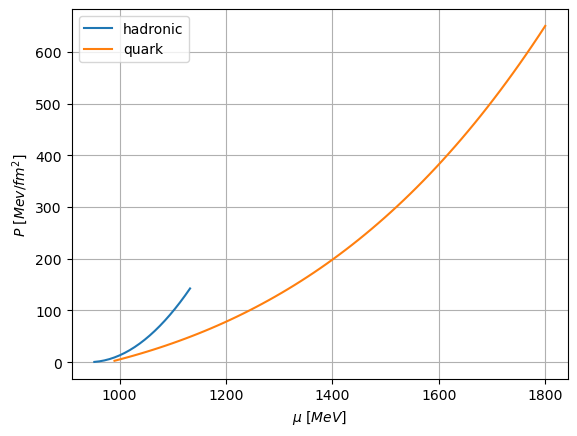

In [15]:
plt.plot(mu, p, label = "hadronic")
plt.plot(chemical_potential, pressure, label = "quark")

plt.xlabel(r"$\mu \ [MeV]$")
plt.ylabel(r"$P \ [Mev/fm^2]$")
#plt.xlim([950,1800])
#plt.ylim([0,600])
plt.legend()
plt.grid()

In [415]:
e_combined,p_combined,mu_combined,cs_combined,P_crit=ef(chemical_potential,pressure,energy_density,mu,p,e)

In [416]:
P_crit

2.632984535139393

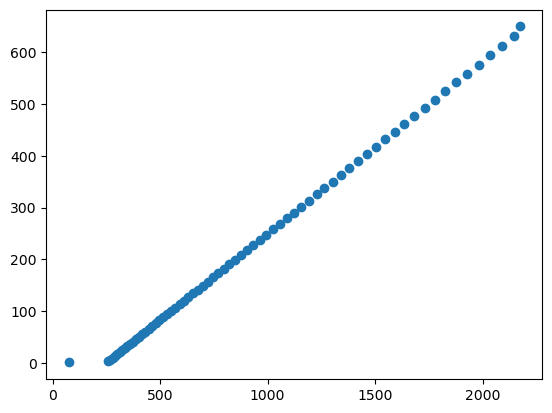

In [412]:
plt.scatter(e_combined,p_combined)

In [205]:
from scipy import interpolate
from scipy.optimize import minimize

In [414]:
def ef(chemical_potential,pressure,energy_density,mu,p,e):
    x1 = np.array(chemical_potential)
    y1 = np.array(pressure)

    x2 = np.array(mu)
    y2 = np.array(e)

    P_q_int_func = interpolate.interp1d(x1, y1)
    P_h_int_func = interpolate.interp1d(x2, y2)

    mu_new = np.linspace(min(x1), max(x1), 1000)
    P_had_array = P_h_int_func(mu_new)
    P_quark_array = P_q_int_func(mu_new)

    # Calculate the difference and find the intersection
    y_diff = np.abs(P_had_array - P_quark_array)
    index_intersect = np.argmin(y_diff)
    x_intersect = mu_new[index_intersect]
    y_intersect = P_had_array[index_intersect]

    #print("The transition point is:","Chemical Potential :", x_intersect,"Pressure :",y_intersect)

    index = (np.abs(chemical_potential - x_intersect)).argmin()

    # Split the arrays at the intersection point
    mu_quark_t = chemical_potential[index:]
    P_quark_t = pressure[index:]
    e_quark_t = energy_density[index:]

    mu_had_t = mu[:index+1]
    P_had_t = p[:index+1]
    e_had_t = e[:index+1]


    e_combined = np.concatenate((e_had_t, e_quark_t))
    p_combined = np.concatenate((P_had_t, P_quark_t))
    mu_combined = np.concatenate((mu_had_t, mu_quark_t))
    #print(len(e_combined))
    #print(len(p_combined))
    cs_combined = np.gradient(p_combined,e_combined)
    P_crit = P_quark_t[0]

    return e_combined,p_combined,mu_combined,cs_combined,P_crit

In [390]:
gamm = np.linspace(3.0,3.1,100)

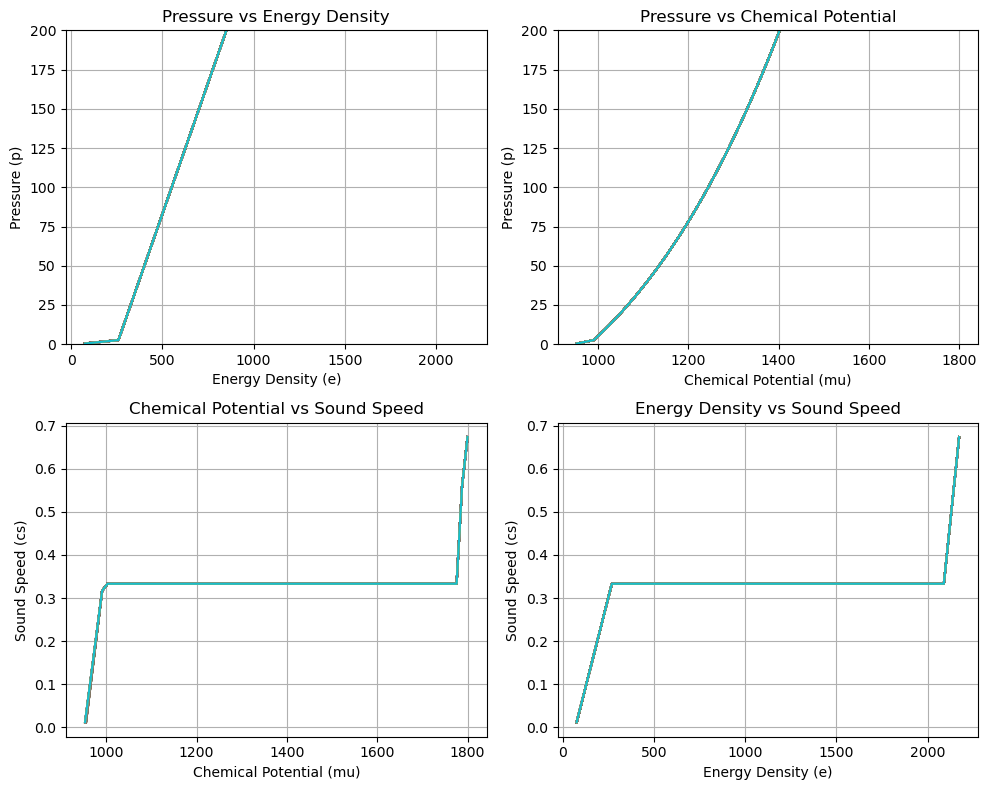

In [395]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))

e_total, p_total, mu_total, cs_total, P_crit_total, mu_crit = [], [], [], [], [], []
for Gam_had in gamm:
    mu=mu_from_nb(n_had,K_had,Gam_had,m0_had)
    p=P_from_nb(n_had,K_had,Gam_had)
    e=e_from_n(n_had,K_had,Gam_had,m0_had)

    e_combined,p_combined,mu_combined,cs_combined,P_crit_value = ef(chemical_potential, pressure, energy_density, mu, p, e)
    # Store concatenated data
    e_total.append(e_combined)
    p_total.append(p_combined)
    mu_total.append(mu_combined)
    cs_total.append(cs_combined)
    P_crit_total.append(P_crit_value)

    


# After the loop, plot concatenated data
for i in range(len(gamm)):
    # Plot 1: Pressure vs Energy Density
    axes[0, 0].plot(e_total[i], p_total[i])

    # Plot 2: Pressure vs Chemical Potential
    axes[0, 1].plot(mu_total[i], p_total[i])

    # Plot 3: Chemical Potential vs Sound Speed
    axes[1, 0].plot(mu_total[i], cs_total[i])

    # Plot 4: Energy Density vs Sound Speed
    axes[1, 1].plot(e_total[i], cs_total[i])

# Adding titles, labels, and legends after the loop

# Plot 1: Pressure vs Energy Density
axes[0, 0].set_title('Pressure vs Energy Density')
axes[0, 0].set_xlabel('Energy Density (e)')
axes[0, 0].set_ylabel('Pressure (p)')
axes[0, 0].set_ylim(0, 200)
axes[0, 0].grid(True)

# Plot 2: Pressure vs Chemical Potential
axes[0, 1].set_title('Pressure vs Chemical Potential')
axes[0, 1].set_xlabel('Chemical Potential (mu)')
axes[0, 1].set_ylabel('Pressure (p)')
axes[0, 1].set_ylim(0, 200)
axes[0, 1].grid(True)

# Plot 3: Chemical Potential vs Sound Speed
axes[1, 0].set_title('Chemical Potential vs Sound Speed')
axes[1, 0].set_ylabel('Sound Speed (cs)')
axes[1, 0].set_xlabel('Chemical Potential (mu)')
axes[1, 0].grid(True)

# Plot 4: Energy Density vs Sound Speed
axes[1, 1].set_title('Energy Density vs Sound Speed')
axes[1, 1].set_ylabel('Sound Speed (cs)')
axes[1, 1].set_xlabel('Energy Density (e)')
axes[1, 1].grid(True)

# Adjust spacing between subplots
plt.tight_layout()

# Show the plot
plt.show()